# Uplift-модель: кому отправлять письмо

**Часть 3.** В сегментном анализе мы смотрели на один признак за раз. Здесь модель учитывает все признаки клиента сразу и для каждого клиента оценивает **uplift** – на сколько письмо повышает вероятность целевого действия именно у него.

Зачем это нужно. Обычная модель отвечает на вопрос «купит ли клиент». Но письмо стоит отправлять не тем, кто купит и так, а тем, у кого оно **меняет** поведение. Uplift-модель ранжирует клиентов по ожидаемой пользе от письма, и тогда рассылку можно ограничить самыми отзывчивыми.

План:
1. Подготовка: выбираем письмо и целевую метрику
2. Три модели uplift (T-learner с логрегрессией, T-learner с градиентным бустингом, преобразование классов) и четвёртая модель по тратам
3. Честная оценка: предсказания для каждого клиента делаются моделью, которая его не видела (кросс-валидация)
4. Qini-кривая и uplift по децилям
5. Деньги: сколько клиентов стоит охватить рассылкой при разной стоимости письма
6. Что модель выучила

In [5]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

paths = glob.glob("/kaggle/input/**/*Hillstrom*.csv", recursive=True) \
     or glob.glob("/kaggle/input/**/*.csv", recursive=True) \
     or glob.glob("../archive/*.csv")
df = pd.read_csv(paths[0])
print("Файл:", paths[0], df.shape)

CONTROL = "No E-Mail"
SEED = 42

Файл: /kaggle/input/datasets/sumittarya/hillstrom-email-marketing/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv (64000, 12)


## 1. Постановка

**Какое письмо моделируем.** Женское письмо (`Womens E-Mail`) против контроля. В сегментном анализе именно его эффект сильно зависел от клиента (хорошо работал для покупательниц женской одежды и новых клиентов), поэтому здесь есть чему учиться. У мужского письма эффект почти одинаков для всех, и таргетинг даёт мало. В конце проверим и его.

**Целевая метрика для обучения: `visit`.** Конверсия редкая (меньше 1%), и по ней модель получила бы слишком мало сигналов и выучила бы шум. Визиты встречаются в 15–20 раз чаще, сигнал стабильнее. Но бизнесу нужны деньги, поэтому качество модели мы дополнительно проверим на реальных тратах (раздел 5).

**Признаки.** Только то, что известно до рассылки: давность и сумма покупок, что покупал (мужское и женское), новичок ли, тип района и канал.

In [6]:
NUM = ["recency", "history", "mens", "womens", "newbie"]
CAT = ["zip_code", "channel"]
FEATURES = NUM + CAT

def make_prep(scale):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("num", StandardScaler() if scale else "passthrough", NUM),
    ])

def prep_data(treat):
    d = df[df.segment.isin([treat, CONTROL])].reset_index(drop=True).copy()
    d["T"] = (d.segment == treat).astype(int)
    return d

d_w = prep_data("Womens E-Mail")
print(d_w["T"].value_counts().rename({1: "письмо", 0: "контроль"}).to_dict())

{'письмо': 21387, 'контроль': 21306}


## 2. Три способа оценить uplift

- **T-learner (логрегрессия).** Две отдельные модели: одна обучается на клиентах с письмом, другая на контроле. Uplift = P(действие | письмо) − P(действие | без письма). Простая и устойчивая модель.
- **T-learner (градиентный бустинг).** То же самое, но модели гибче и могут найти сложные взаимодействия признаков.
- **Преобразование классов (логрегрессия).** Одна модель на всех клиентах. Новая цель: 1, если клиент с письмом совершил действие или клиент без письма его не совершил, иначе 0. При равных группах uplift = 2 × P(цель = 1) − 1. Это классический метод, который напрямую учится на разнице между группами.

Чтобы оценка была честной, каждого клиента оцениваем моделью, обученной на **других** клиентах (5-кратная кросс-валидация). Так мы не проверяем модель на данных, которые она уже видела.

In [7]:
def gb_clf():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                          min_samples_leaf=100, random_state=SEED)

def gb_reg():
    return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=150,
                                         min_samples_leaf=100, random_state=SEED)

def lr_clf():
    return LogisticRegression(max_iter=2000, C=1.0)

def fit_predict(train, test, target, kind):
    X_tr, X_te = train[FEATURES], test[FEATURES]
    if kind in ("t_lr", "t_gb", "t_gb_spend"):
        scale = kind == "t_lr"
        est = {"t_lr": lr_clf, "t_gb": gb_clf, "t_gb_spend": gb_reg}[kind]
        preds = {}
        for t in (0, 1):
            m = make_pipeline(make_prep(scale), est())
            sub = train[train["T"] == t]
            m.fit(sub[FEATURES], sub[target])
            preds[t] = m.predict(X_te) if kind == "t_gb_spend" else m.predict_proba(X_te)[:, 1]
        return preds[1] - preds[0]
    if kind == "ct_lr":
        m = make_pipeline(make_prep(True), lr_clf())
        m.fit(X_tr, (train[target] == train["T"]).astype(int))
        return 2 * m.predict_proba(X_te)[:, 1] - 1
    raise ValueError(kind)

def oof_scores(d, target, kind, n_splits=5):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED)
    strat = d["T"].astype(str) + "_" + (d[target] > 0).astype(str)
    score = np.zeros(len(d))
    for tr, te in skf.split(d, strat):
        score[te] = fit_predict(d.iloc[tr], d.iloc[te], target, kind)
    return score

In [8]:
MODELS = {
    "T-learner, логрегрессия": ("t_lr", "visit"),
    "T-learner, бустинг": ("t_gb", "visit"),
    "Преобразование классов, логрегрессия": ("ct_lr", "visit"),
    "T-learner, бустинг по тратам": ("t_gb_spend", "spend"),
}

def run_models(d):
    out = {}
    for name, (kind, target) in MODELS.items():
        out[name] = oof_scores(d, target, kind)
    return out

scores_w = run_models(d_w)
pd.DataFrame(scores_w).describe().T

,count,mean,std,min,25%,50%,75%,max
"T-learner, логрегрессия","42,693.0000",0.0454,0.0340,-0.1146,0.0177,0.0612,0.0762,0.0987
"T-learner, бустинг","42,693.0000",0.0457,0.0393,-0.1227,0.0148,0.0460,0.0765,0.2554
"Преобразование классов, логрегрессия","42,693.0000",0.0438,0.0318,-0.0560,0.0143,0.0517,0.0726,0.1131
"T-learner, бустинг по тратам","42,693.0000",0.4460,0.5109,-4.3514,0.2538,0.4353,0.6399,5.1536


Четвёртая модель, T-learner по тратам, добавлена для сравнения: она учится предсказывать сразу деньги, а не визиты. Деньги шумнее визитов, и интересно проверить, выигрывает ли она от прямой цели.

## 3. Qini-кривая

Как читать. Клиентов сортируем по предсказанному uplift от самого отзывчивого к наименее отзывчивому. Кривая показывает, сколько **дополнительных визитов** мы получим, если отправим письмо первым k% клиентов.

- Пунктирная прямая: случайный порядок (охватываем клиентов в случайной очереди).
- Чем выше кривая над прямой, тем лучше модель отличает отзывчивых клиентов.
- Площадь между кривой и прямой (Qini AUC gap) – сводная метрика качества. Для неё считаем бутстрап-интервал.

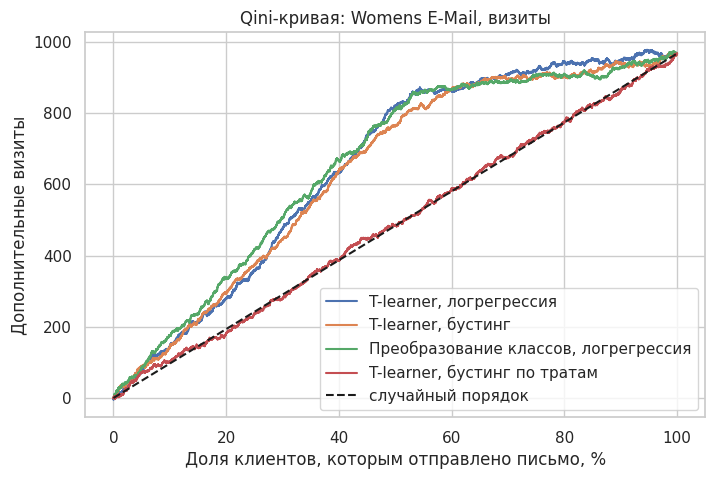

,модель,Qini AUC gap,CI95 низ,CI95 верх
2,"Преобразование классов, логрегрессия",172.6019,131.2231,209.7832
0,"T-learner, логрегрессия",167.6760,126.3266,207.2135
1,"T-learner, бустинг",155.0600,112.0457,188.8909
3,"T-learner, бустинг по тратам",1.9879,-31.1343,34.7318


In [9]:
def qini_curve(y, t, score):
    order = np.argsort(-score, kind="stable")
    y, t = y[order], t[order]
    cum_t, cum_c = np.cumsum(t), np.cumsum(1 - t)
    yt, yc = np.cumsum(y * t), np.cumsum(y * (1 - t))
    q = yt - yc * cum_t / np.maximum(cum_c, 1)
    frac = np.arange(1, len(y) + 1) / len(y)
    return frac, q

def qini_gap(y, t, score):
    frac, q = qini_curve(y, t, score)
    return np.mean(q - q[-1] * frac)

def bootstrap_gap(y, t, score, n_boot=200, seed=0):
    rng = np.random.default_rng(seed)
    n = len(y)
    gaps = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        gaps[i] = qini_gap(y[idx], t[idx], score[idx])
    return np.percentile(gaps, [2.5, 97.5])

def evaluate_models(d, scores, outcome="visit"):
    y, t = d[outcome].to_numpy(float), d["T"].to_numpy()
    rows = []
    for name, s in scores.items():
        lo, hi = bootstrap_gap(y, t, s)
        rows.append({"модель": name, "Qini AUC gap": qini_gap(y, t, s), "CI95 низ": lo, "CI95 верх": hi})
    return pd.DataFrame(rows).sort_values("Qini AUC gap", ascending=False)

def plot_qini(d, scores, outcome="visit", title=""):
    y, t = d[outcome].to_numpy(float), d["T"].to_numpy()
    plt.figure(figsize=(8, 5))
    for name, s in scores.items():
        frac, q = qini_curve(y, t, s)
        plt.plot(frac * 100, q, label=name)
    plt.plot([0, 100], [0, q[-1]], "k--", label="случайный порядок")
    plt.xlabel("Доля клиентов, которым отправлено письмо, %")
    plt.ylabel("Дополнительные визиты")
    plt.title(title); plt.legend(); plt.show()

plot_qini(d_w, scores_w, "visit", "Qini-кривая: Womens E-Mail, визиты")
evaluate_models(d_w, scores_w, "visit")

Если доверительный интервал gap не включает ноль, модель ранжирует клиентов лучше случайного порядка.

Те же модели оцениваем по **тратам** (в долларах). Это самая важная для бизнеса метрика, но и самая шумная, поэтому доверительные интервалы будут шире.

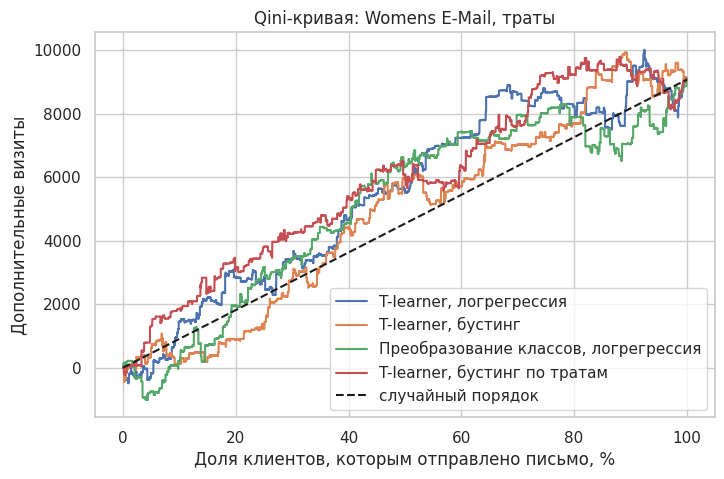

,модель,Qini AUC gap,CI95 низ,CI95 верх
3,"T-learner, бустинг по тратам","1,277.5228",-189.9043,"3,032.5546"
0,"T-learner, логрегрессия",906.5129,-922.0336,"2,681.8722"
2,"Преобразование классов, логрегрессия",519.4676,"-1,349.4389","2,182.7046"
1,"T-learner, бустинг",318.8099,"-1,666.8819","1,950.0382"


In [10]:
plot_qini(d_w, scores_w, "spend", "Qini-кривая: Womens E-Mail, траты")
evaluate_models(d_w, scores_w, "spend")

## 4. Uplift по децилям

Самая наглядная проверка: клиентов делим на 10 групп по предсказанному uplift (1 – самые отзывчивые по мнению модели). В каждой группе считаем **реальный** эффект письма как разницу долей визитов в группе с письмом и контроле.
Если модель работает, эффект должен убывать от первой группы к десятой.

Лучшая модель по Qini для визитов: Преобразование классов, логрегрессия


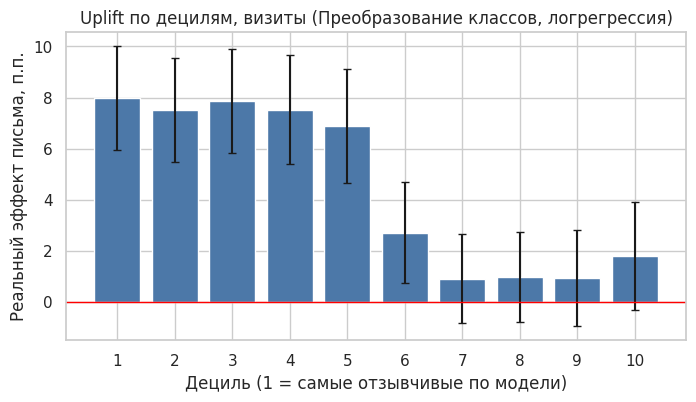

,дециль,клиентов,эффект,se,предсказанный uplift
0,1,4270,0.0799,0.0103,0.0874
1,2,4269,0.0752,0.0104,0.0781
2,3,4269,0.0787,0.0103,0.0726
3,4,4269,0.0753,0.0109,0.0672
4,5,4270,0.0690,0.0113,0.0588
5,6,4269,0.0272,0.0101,0.0360
6,7,4269,0.0092,0.0089,0.0209
7,8,4269,0.0099,0.0090,0.0143
8,9,4269,0.0094,0.0096,0.0083
9,10,4270,0.0180,0.0108,-0.0060


In [11]:
def decile_table(d, score, outcome="visit", q=10):
    x = d.assign(score=score)
    x["дециль"] = pd.qcut(x["score"].rank(method="first", ascending=False), q, labels=range(1, q + 1))
    rows = []
    for k, g in x.groupby("дециль", observed=True):
        gt, gc = g[g["T"] == 1][outcome], g[g["T"] == 0][outcome]
        diff = gt.mean() - gc.mean()
        se = np.sqrt(gt.var() / len(gt) + gc.var() / len(gc))
        rows.append({"дециль": int(k), "клиентов": len(g), "эффект": diff, "se": se,
                     "предсказанный uplift": g["score"].mean()})
    return pd.DataFrame(rows)

def plot_deciles(tab, title, unit_scale=100, unit="п.п."):
    plt.figure(figsize=(8, 4))
    plt.bar(tab["дециль"], tab["эффект"] * unit_scale, yerr=1.96 * tab["se"] * unit_scale, capsize=3, color="#4c78a8")
    plt.axhline(0, color="red", lw=1)
    plt.xticks(tab["дециль"])
    plt.xlabel("Дециль (1 = самые отзывчивые по модели)"); plt.ylabel(f"Реальный эффект письма, {unit}")
    plt.title(title); plt.show()

best_visit = evaluate_models(d_w, scores_w, "visit").iloc[0]["модель"]
print("Лучшая модель по Qini для визитов:", best_visit)
tab = decile_table(d_w, scores_w[best_visit], "visit")
plot_deciles(tab, f"Uplift по децилям, визиты ({best_visit})")
tab

## 5. Деньги: сколько клиентов стоит охватить

Для бизнеса главный вопрос такой: **если письмо стоит денег, кому его отправлять?** Мы знаем реальные траты клиентов, поэтому можем посчитать прибыль на 1 000 клиентов базы при рассылке только верхним k% клиентов по модели:

> прибыль = 1 000 × k × (дополнительные траты на клиента в охваченной группе − стоимость письма)

Дополнительные траты берём из данных: разница средних трат в группе с письмом и в контроле среди охваченных. Остальные клиенты письма не получают.

**Стоимость письма в данных не указана.** Мы подставляем разные значения (от 0,05 до 0,40 доллара), чтобы увидеть, при какой цене таргетинг начинает окупаться.

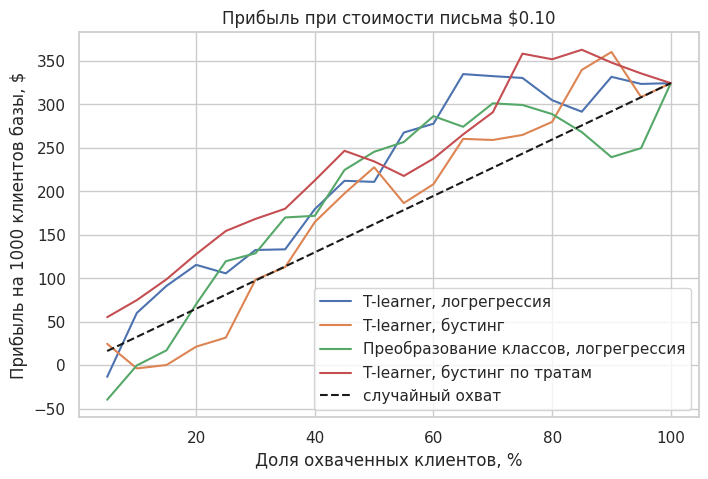

In [12]:
def profit_curve(d, score, cost, grid=np.linspace(0.05, 1.0, 20)):
    order = np.argsort(-score, kind="stable")
    x = d.iloc[order].reset_index(drop=True)
    rows = []
    for k in grid:
        top = x.iloc[: int(round(k * len(x)))]
        up = top[top["T"] == 1]["spend"].mean() - top[top["T"] == 0]["spend"].mean()
        rows.append({"доля охвата": k, "доп. траты на клиента": up, "прибыль на 1000 клиентов": 1000 * k * (up - cost)})
    return pd.DataFrame(rows)

COST = 0.10
plt.figure(figsize=(8, 5))
for name, s in scores_w.items():
    pc = profit_curve(d_w, s, COST)
    plt.plot(pc["доля охвата"] * 100, pc["прибыль на 1000 клиентов"], label=name)
overall_up = d_w[d_w["T"] == 1]["spend"].mean() - d_w[d_w["T"] == 0]["spend"].mean()
ks = np.linspace(0.05, 1.0, 20)
plt.plot(ks * 100, 1000 * ks * (overall_up - COST), "k--", label="случайный охват")
plt.xlabel("Доля охваченных клиентов, %"); plt.ylabel("Прибыль на 1000 клиентов базы, $")
plt.title(f"Прибыль при стоимости письма ${COST:.2f}"); plt.legend(); plt.show()

### Честная оценка выигрыша от таргетинга

Если выбирать лучший охват по тем же данным, на которых считается прибыль, мы выбираем максимум шумной кривой, и выигрыш получается завышенным. Поэтому оцениваем честно:
1. Случайно делим клиентов пополам.
2. На первой половине выбираем охват, дающий максимум прибыли.
3. На второй половине считаем прибыль с этим охватом и сравниваем с рассылкой всем.
4. Повторяем 50 раз и берём среднее.

Для сравнения добавлено **простое правило без ML**: слать письмо только тем, кто раньше покупал женские товары. Правило задано заранее одним признаком, выбирать охват не нужно.

In [13]:
def honest_gain(d, score, cost, n_rep=50, seed=0):
    rng = np.random.default_rng(seed)
    grid = np.linspace(0.05, 1.0, 20)
    gains = []
    for _ in range(n_rep):
        mask = rng.random(len(d)) < 0.5
        A, B = d[mask], d[~mask]
        pa = profit_curve(A, score[mask], cost, grid)
        k_star = pa.loc[pa["прибыль на 1000 клиентов"].idxmax(), "доля охвата"]
        p_k = profit_curve(B, score[~mask], cost, [k_star])["прибыль на 1000 клиентов"].iloc[0]
        p_all = profit_curve(B, score[~mask], cost, [1.0])["прибыль на 1000 клиентов"].iloc[0]
        gains.append(p_k - p_all)
    return np.mean(gains)

def rule_gain(d, mask, cost):
    up_all = d[d["T"] == 1]["spend"].mean() - d[d["T"] == 0]["spend"].mean()
    g = d[mask]
    up = g[g["T"] == 1]["spend"].mean() - g[g["T"] == 0]["spend"].mean()
    return 1000 * mask.mean() * (up - cost) - 1000 * (up_all - cost)

COSTS = [0.05, 0.10, 0.20, 0.30, 0.40]
table = {}
for name, s in scores_w.items():
    table[name] = [honest_gain(d_w, s, c) for c in COSTS]
table["Правило: слать, если покупал женское"] = [rule_gain(d_w, d_w["womens"] == 1, c) for c in COSTS]
gain_table = pd.DataFrame(table, index=[f"${c:.2f}" for c in COSTS]).T
gain_table.columns.name = "стоимость письма"
print("Выигрыш в $ на 1000 клиентов базы по сравнению с рассылкой всем клиентам")
gain_table

Выигрыш в $ на 1000 клиентов базы по сравнению с рассылкой всем клиентам


стоимость письма,$0.05,$0.10,$0.20,$0.30,$0.40
"T-learner, логрегрессия",-50.3960,-43.3035,-23.6451,-1.4931,35.8387
"T-learner, бустинг",-4.6311,-4.9118,-14.8617,-18.7415,-27.4638
"Преобразование классов, логрегрессия",-57.8617,-60.1347,-59.9687,-35.0687,-1.2605
"T-learner, бустинг по тратам",-13.0172,-14.0223,-6.4372,-5.7472,9.8301
"Правило: слать, если покупал женское",-103.1520,-80.5956,-35.4828,9.6300,54.7427


In [14]:
print("Прибыль на 1000 клиентов, если слать всем:")
pd.Series({f"${c:.2f}": 1000 * (overall_up - c) for c in COSTS})

Прибыль на 1000 клиентов, если слать всем:


$0.05   374.4122
$0.10   324.4122
$0.20   224.4122
$0.30   124.4122
$0.40    24.4122
dtype: float64

Положительное число означает, что таргетинг дал больше прибыли, чем рассылка всем. Чем дороже письмо, тем сильнее выигрыш от таргетинга: при дешёвом письме выгодно слать почти всем, при дорогом нужно отбирать.

## 6. Что модель выучила

Сравним средний предсказанный uplift в сегментах с тем, что мы видели в сегментном анализе. Если модель предсказывает то же самое, она выучила осмысленную закономерность.

In [15]:
res = d_w.assign(score=scores_w[best_visit])
res["buyer_type"] = np.select(
    [(res.mens == 1) & (res.womens == 0), (res.mens == 0) & (res.womens == 1), (res.mens == 1) & (res.womens == 1)],
    ["only_mens", "only_womens", "both"], default="neither")
res["newbie_label"] = res["newbie"].map({0: "existing", 1: "new"})

def seg_compare(col):
    rows = []
    for v, g in res.groupby(col):
        gt, gc = g[g["T"] == 1]["visit"], g[g["T"] == 0]["visit"]
        rows.append({"сегмент": f"{col} = {v}", "клиентов": len(g),
                     "предсказанный uplift, п.п.": g["score"].mean() * 100,
                     "реальный эффект, п.п.": (gt.mean() - gc.mean()) * 100})
    return pd.DataFrame(rows)

pd.concat([seg_compare("buyer_type"), seg_compare("newbie_label")], ignore_index=True)

,сегмент,клиентов,"предсказанный uplift, п.п.","реальный эффект, п.п."
0,buyer_type = both,4267,7.5244,7.1103
1,buyer_type = only_mens,19260,1.1665,1.1078
2,buyer_type = only_womens,19166,6.8994,7.3985
3,newbie_label = existing,21235,3.9632,4.0123
4,newbie_label = new,21458,4.7837,5.0417


## 7. Проверка на мужском письме

Повторяем всё то же самое для `Mens E-Mail`. Из сегментного анализа мы ожидаем, что здесь модель даст мало, потому что эффект почти одинаков для всех.

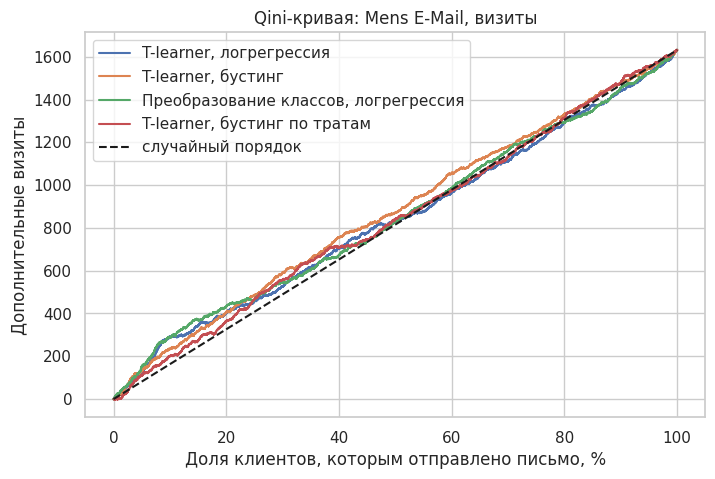

,модель,Qini AUC gap,CI95 низ,CI95 верх
1,"T-learner, бустинг",53.1934,12.2838,92.7742
2,"Преобразование классов, логрегрессия",30.2597,-9.6441,82.6234
3,"T-learner, бустинг по тратам",21.8870,-22.6755,64.6470
0,"T-learner, логрегрессия",20.0088,-17.6492,62.1450


In [16]:
d_m = prep_data("Mens E-Mail")
scores_m = run_models(d_m)
plot_qini(d_m, scores_m, "visit", "Qini-кривая: Mens E-Mail, визиты")
evaluate_models(d_m, scores_m, "visit")

In [ ]:
best_m = evaluate_models(d_m, scores_m, "visit").iloc[0]["модель"]
plot_deciles(decile_table(d_m, scores_m[best_m], "visit"), f"Uplift по децилям, Mens E-Mail ({best_m})")

## Выводы по uplift-модели

**1. Модель хорошо отличает отзывчивых клиентов по визитам.** Для женского письма Qini AUC gap по визитам значимо выше нуля у всех трёх моделей: преобразование классов 173 [131; 210], T-learner с логрегрессией 168 [126; 207], T-learner с бустингом 155 [112; 189] (в скобках 95%-й интервал). Разница между этими тремя моделями несущественна: интервалы почти полностью перекрываются, а простая логрегрессия не хуже бустинга.

**2. Реальный эффект убывает по децилям.** В первых пяти децилях письмо увеличивает долю визитов на 6,9–8,0 п.п., в остальных пяти только на 0,9–2,7 п.п. (в десятом дециле 1,8 п.п. при широком интервале). То есть клиентов делят на две группы: у половины письмо работает сильно, у другой половины почти нет.

**3. Модель выучила то же, что мы видели в сегментном анализе.** Предсказанный uplift совпадает с реальным: покупали только женское 6,9 против 7,4 п.п.; только мужское 1,2 против 1,1 п.п.; новые клиенты 4,8 против 5,0 п.п.; существующие 4,0 против 4,0 п.п. Основной источник различий между клиентами: **покупал ли клиент женские товары**.

**4. По деньгам таргетинг не окупился при дешёвом письме.** Траты шумные (покупают меньше 1% клиентов), и все четыре модели ранжируют по тратам не лучше случайного порядка (Qini по тратам: интервалы включают ноль). Честная оценка (охват выбирается на одной половине данных, проверяется на другой) показывает:

| Стоимость письма | Что выгоднее |
|---|---|
| $0,05–$0,20 | Слать всем: все модели и правило проигрывают рассылке всем (от −5 до −103 $ на 1000 клиентов) |
| $0,30 | Почти всё равно; выигрывает только простое правило (+9,6 $) |
| $0,40 | Простое правило (+54,7 $), T-learner с логрегрессией (+35,8 $), модель по тратам (+9,8 $) |

Прибыль при рассылке всем при этом составляет $374 на 1000 клиентов при цене письма $0,05 и падает до $24 при цене $0,40. У реальной email-рассылки письмо стоит копейки, поэтому в такой постановке выгоднее слать женское письмо всем.

**5. Простое правило не хуже модели.** Правило «слать женское письмо только тем, кто покупал женское» при дорогом письме даёт больший выигрыш, чем любая модель. Причина в том, что неоднородность эффекта в данных почти целиком объясняется одним признаком. Модель его находит, но на остальных признаках дополнительной пользы не получает: она лишь добавляет шум.

**6. Мужское письмо.** Там ранжирование заметно слабее: значимо выше случайного только T-learner с бустингом (53 [12; 93]), остальные интервалы включают ноль. Это согласуется с сегментным анализом: эффект мужского письма почти одинаков для всех, и таргетинг почти ничего не даёт.

**Оговорки.**
- Данные охватывают две недели, а траты очень разрежены, поэтому выводы по деньгам менее надёжны, чем по визитам.
- Стоимость письма в данных не указана, мы перебирали значения.
- Охват в разделе 5 выбирался на половине данных; для бустинга результаты менее устойчивы (он чувствителен к разбиению и случайности), логистические модели стабильны.
- Uplift по визитам не обязательно приводит к деньгам: клиент мог зайти, но ничего не купить.

**Рекомендация для бизнеса.** Если письмо стоит копейки, слать женское письмо всем, а мужское тоже всем: оба дают положительную прибыль. Если стоимость отправки заметно выше (около $0,30 и более) или нужно ограничить объём рассылки, использовать простое правило по типу покупателя. Сложная uplift-модель на этих данных не оправдывает усложнения, но подтверждает, откуда берётся разброс эффекта.